# Train on the Google Drive dataset (Colab runner)
**Runtime → Change runtime type → GPU (T4)**, then *Run all*.

Before running: put this whole project folder in your Drive (e.g. `MyDrive/brain_tumor_mri_project`) and make sure the dataset folder (class sub-folders such as `glioma/`, `meningioma/`, `notumor/`, `pituitary/`, optionally inside `Training/` and `Testing/`) is in your Drive too.

In [11]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT = "/content/drive/MyDrive/brain_tumor_mri_project/brain_tumor_mri_project"   # <-- this project folder
DATA_SRC = "/content/drive/MyDrive/Tumour"                    # <-- the dataset folder from the Drive link
assert __import__("os").path.isdir(PROJECT),  f"Project folder not found: {PROJECT}"
assert __import__("os").path.isdir(DATA_SRC), f"Dataset folder not found: {DATA_SRC}"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# Copy the dataset to the fast local disk (reading thousands of files straight from Drive is slow)
!mkdir -p /content/data && cp -r "{DATA_SRC}/." /content/data/
!find /content/data -type f | wc -l
!ls /content/data

2447
README.dataset.txt  test  train  valid


In [13]:
!ls /content/drive/MyDrive/brain_tumor_mri_project
!find /content/drive/MyDrive -maxdepth 4 -name "train.py"

brain_tumor_mri_project
/content/drive/MyDrive/brain_tumor_mri_project/brain_tumor_mri_project/src/train.py


In [14]:
%cd {PROJECT}
!pip install -q h5py
!python -m src.train --data_dir /content/data --epochs 25 --ft_epochs 10 --out_dir .
# add ,inceptionv3 to --models to also train InceptionV3

/content/drive/MyDrive/brain_tumor_mri_project/brain_tumor_mri_project
I0000 00:00:1791819115.226146   10297 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Found 2443 readable images; removed 0 exact duplicates -> 2443 images
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
            train  val  test
label                       
glioma        616  109    80
meningioma    410   72    63
no_tumor      369   65    49
pituitary     472   84    54
W0000 00:00:1791819121.385275   10297 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1791819121.387035   10297 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 M

,model,accuracy,precision,recall,f1,val_f1,params_M,size_MB,ms_per_image
0,custom_cnn,0.7927,0.7884,0.8044,0.7892,0.8070,1.2420,15.0542,3.4849
1,mobilenetv2,0.8455,0.8481,0.8491,0.8434,0.8851,2.5869,25.4533,3.1579
2,resnet50v2,0.8902,0.8941,0.8888,0.8884,0.9105,24.0904,216.3800,5.5629
3,efficientnetb0,0.7195,0.7686,0.6987,0.6888,0.7578,4.3785,32.5057,3.6261


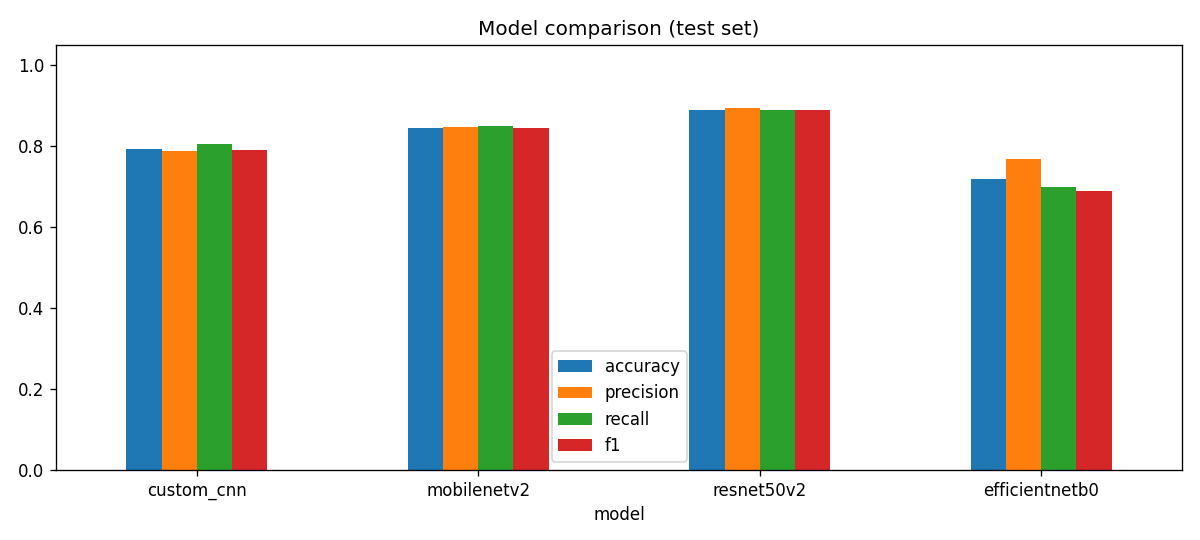

results/custom_cnn_confusion_matrix.png


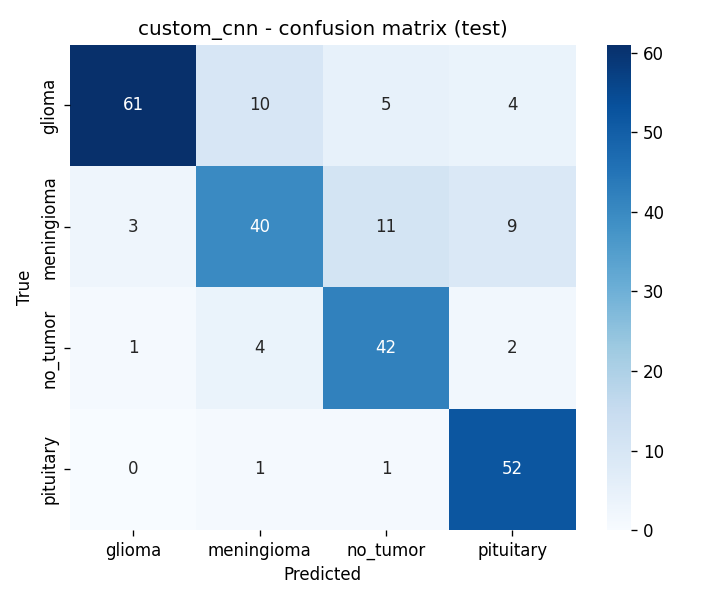

results/efficientnetb0_confusion_matrix.png


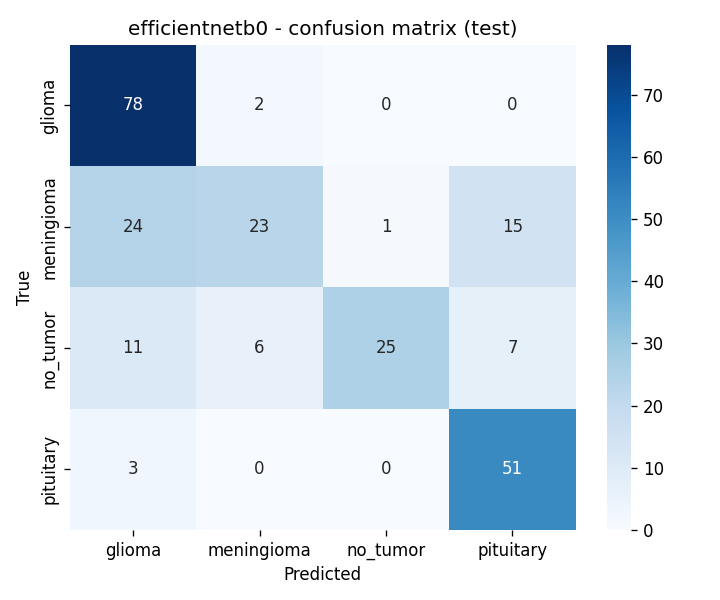

results/mobilenetv2_confusion_matrix.png


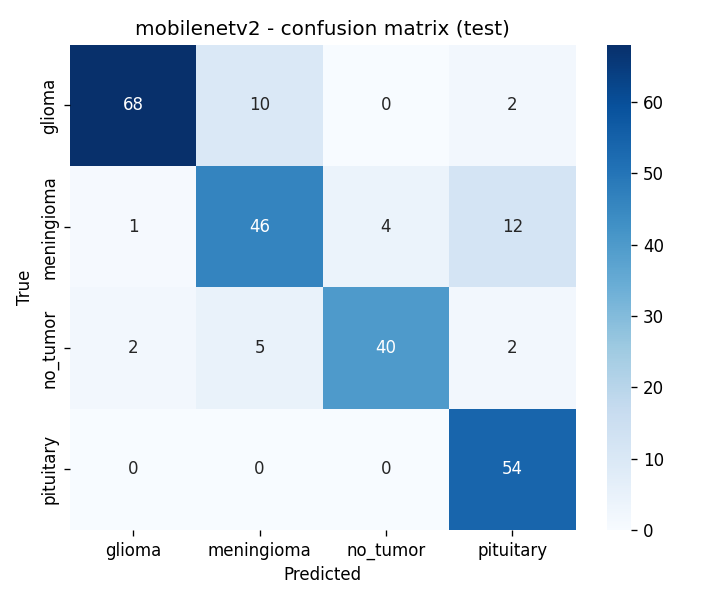

results/resnet50v2_confusion_matrix.png


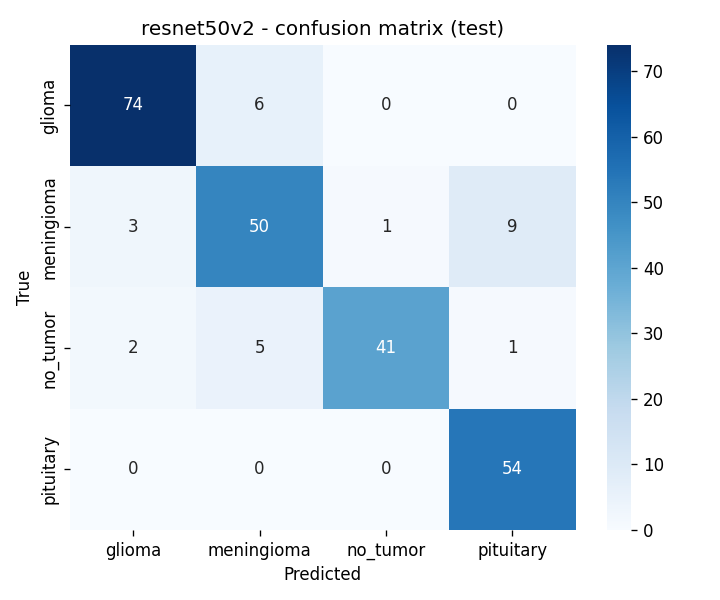

results/custom_cnn_history.png


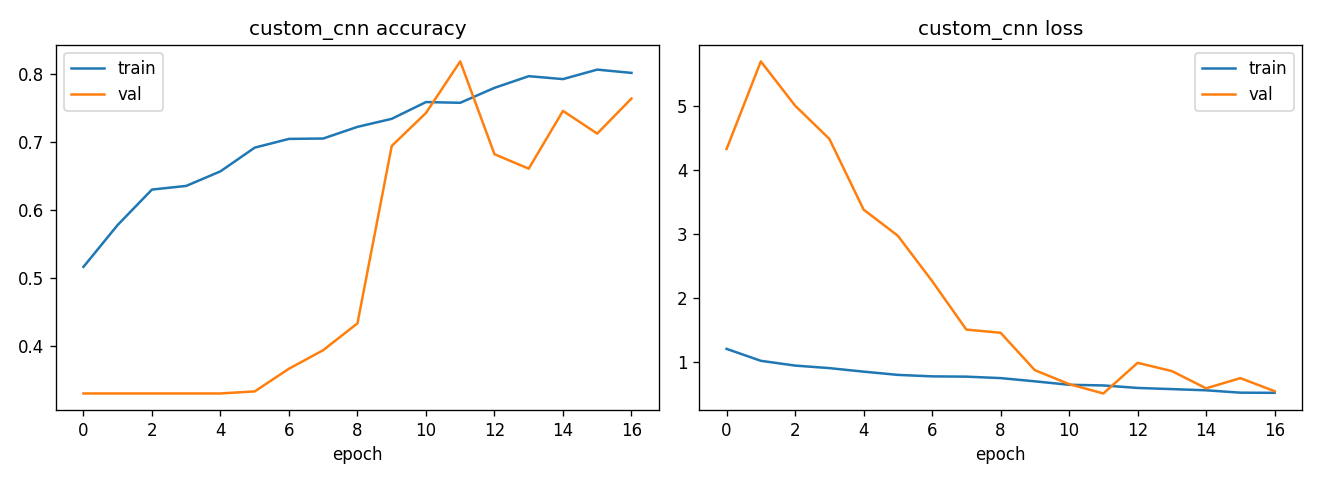

results/efficientnetb0_history.png


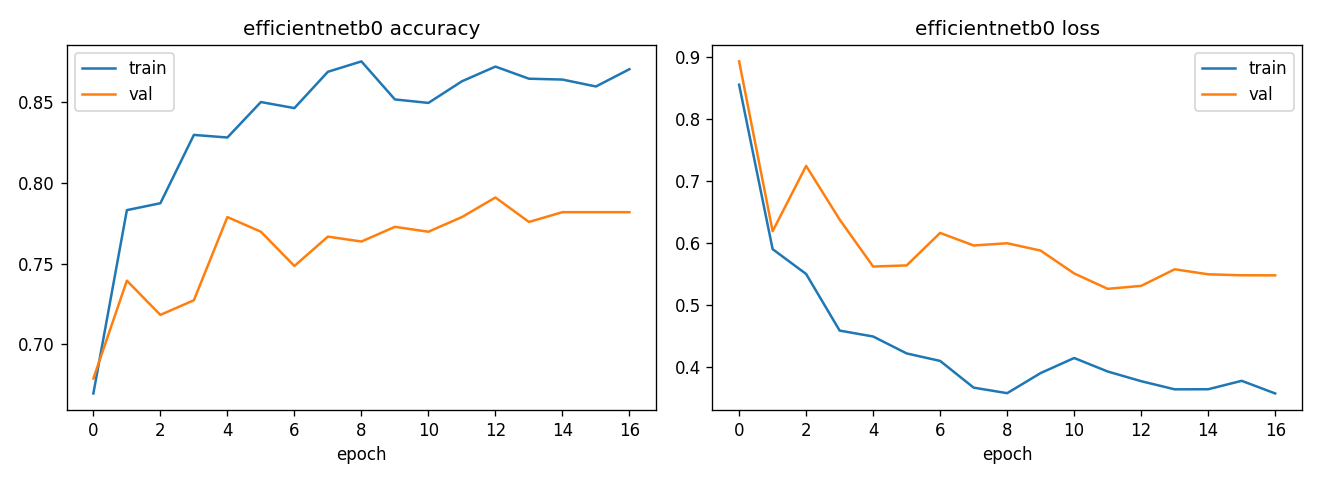

results/mobilenetv2_history.png


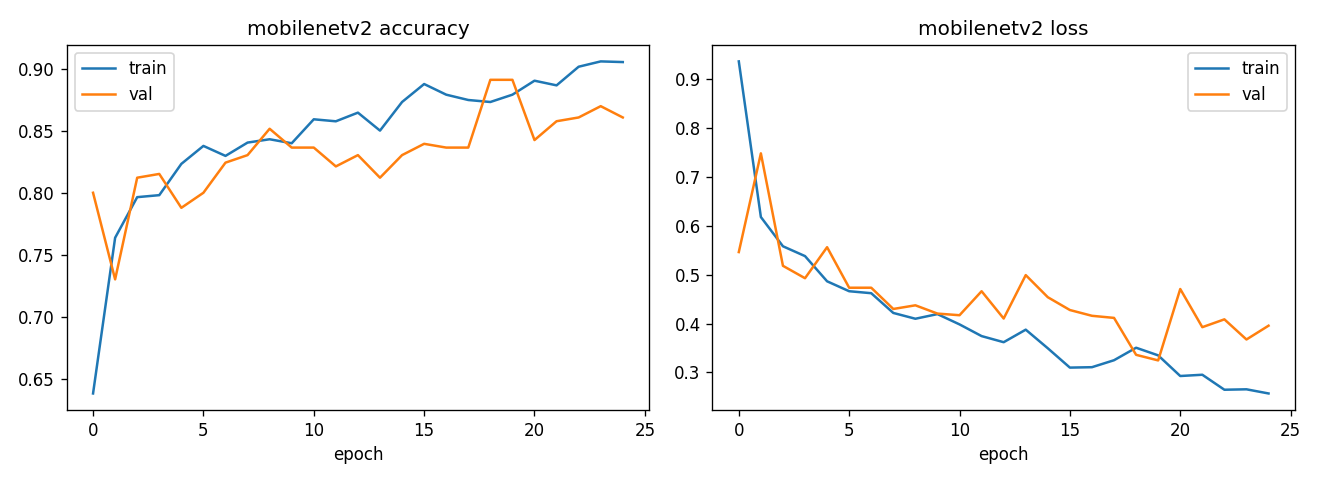

results/resnet50v2_history.png


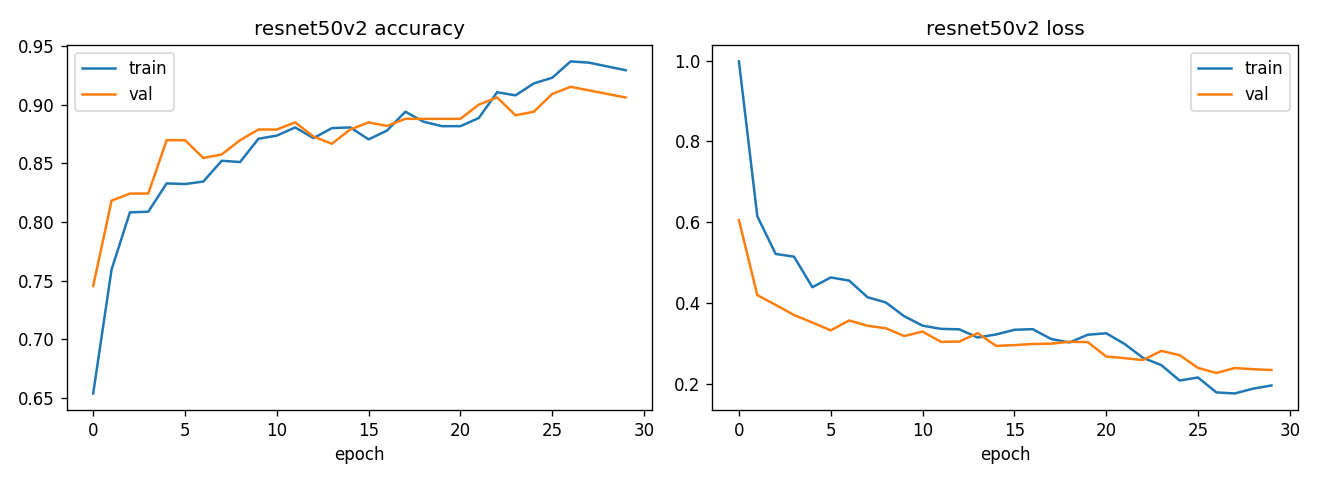

In [15]:
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv("results/model_comparison.csv"))
display(Image("results/model_comparison.png"))
import glob
for f in sorted(glob.glob("results/*_confusion_matrix.png")) + sorted(glob.glob("results/*_history.png")):
    print(f); display(Image(f))

In [16]:
# Models (.h5), class names and all result files are now saved inside your Drive project folder:
!ls -la models results | head -50
# Run the web app locally:  pip install -r requirements.txt && streamlit run app.py

models:
total 493929
drwx------ 2 root root      4096 Oct 12 15:50 .
drwx------ 6 root root      4096 Oct 12 01:43 ..
-rw------- 1 root root 216379952 Oct 12 15:50 best_model.h5
-rw------- 1 root root        49 Oct 12 15:32 class_names.json
-rw------- 1 root root  15054224 Oct 12 15:36 custom_cnn.h5
-rw------- 1 root root  32505720 Oct 12 15:49 efficientnetb0.h5
-rw------- 1 root root         0 Oct 12 01:38 .gitkeep
-rw------- 1 root root  25453320 Oct 12 15:40 mobilenetv2.h5
-rw------- 1 root root 216379952 Oct 12 15:46 resnet50v2.h5

results:
total 426
drwx------ 2 root root  4096 Oct 12 15:50 .
drwx------ 6 root root  4096 Oct 12 01:43 ..
-rw------- 1 root root   434 Oct 12 15:38 custom_cnn_classification_report.txt
-rw------- 1 root root 34831 Oct 12 15:38 custom_cnn_confusion_matrix.png
-rw------- 1 root root  1826 Oct 12 15:38 custom_cnn_history.json
-rw------- 1 root root 51953 Oct 12 15:38 custom_cnn_history.png
-rw------- 1 root root   434 Oct 12 15:50 efficientnetb0_classific

In [17]:
R = "/content/drive/MyDrive/brain_tumor_mri_project/brain_tumor_mri_project/results"
!cat "{R}/resnet50v2_classification_report.txt"
print("-" * 60)
!cat "{R}/mobilenetv2_classification_report.txt"
print("-" * 60)
!cat "{R}/custom_cnn_classification_report.txt"

              precision    recall  f1-score   support

      glioma       0.94      0.93      0.93        80
  meningioma       0.82      0.79      0.81        63
    no_tumor       0.98      0.84      0.90        49
   pituitary       0.84      1.00      0.92        54

    accuracy                           0.89       246
   macro avg       0.89      0.89      0.89       246
weighted avg       0.89      0.89      0.89       246
------------------------------------------------------------
              precision    recall  f1-score   support

      glioma       0.96      0.85      0.90        80
  meningioma       0.75      0.73      0.74        63
    no_tumor       0.91      0.82      0.86        49
   pituitary       0.77      1.00      0.87        54

    accuracy                           0.85       246
   macro avg       0.85      0.85      0.84       246
weighted avg       0.86      0.85      0.85       246
------------------------------------------------------------
          